Configuraciones para garantizar compatibilidad con las versiones de Python y Keras

In [ ]:
import sys

assert sys.version_info >= (3, 7)

In [ ]:
from packaging import version


In [ ]:
IS_COLAB = "google.colab" in sys.modules
if IS_COLAB:
    import os
    os.environ["TF_USE_LEGACY_KERAS"] = "1"
    import tf_keras

And TensorFlow ≥ 2.8:

In [ ]:
import tensorflow as tf

assert version.parse(tf.__version__) >= version.parse("2.8.0")

In [ ]:
import matplotlib.pyplot as plt


In [ ]:
if not tf.config.list_physical_devices('GPU'):
    print("No GPU was detected. Neural nets can be very slow without a GPU.")
    if "google.colab" in sys.modules:
        print("Go to Runtime > Change runtime and select a GPU hardware "
              "accelerator.")
#    if "kaggle_secrets" in sys.modules:
#        print("Go to Settings > Accelerator and select GPU.")

Carga del Data Ser Fashion MNIST


In [ ]:
import numpy as np
fashion_mnist = tf.keras.datasets.fashion_mnist.load_data()
(X_train_full, y_train_full), (X_test, y_test) = fashion_mnist
X_train_full = X_train_full.astype(np.float32) / 255
X_test = X_test.astype(np.float32) / 255
X_train, X_valid = X_train_full[:-5000], X_train_full[-5000:]
y_train, y_valid = y_train_full[:-5000], y_train_full[-5000:]

4422102/4422102 [==============================] - 0s 0us/step


Visualizemos algunas imágenes:

In [ ]:
def plot_multiple_images(images, n_cols=None):
    n_cols = n_cols or len(images)
    n_rows = (len(images) - 1) // n_cols + 1
    if images.shape[-1] == 1:
        images = images.squeeze(axis=-1)
    plt.figure(figsize=(n_cols, n_rows))
    for index, image in enumerate(images):
        plt.subplot(n_rows, n_cols, index + 1)
        plt.imshow(image, cmap="binary")
        plt.axis("off")



#Modelos de Difusión

A partir de una imagen del conjunto de datos, en cada intervalo de tiempo t, el proceso de difusión añade ruido gaussiano con media 0 y varianza βt. El modelo se entrena para revertir este proceso. Más específicamente, dada una imagen ruidosa generada por el proceso de avance y dado el tiempo t, el modelo se entrena para predecir el ruido total añadido a la imagen original, escalado a varianza 1.

En el artículo [DDPM paper](https://arxiv.org/abs/2006.11239) se incrementa  $\beta_t$ de $\beta_1$ = 0.0001 a $\beta_T = $0.02 ($T$ es el último valor), en el artículo mejorado [Improved DDPM paper](https://arxiv.org/pdf/2102.09672.pdf) se sugiere lo siguiente $\cos^2(\ldots)$ para la programación, lo cual gradualmente decrementa $\bar{\alpha_t} = \prod_{i=0}^{t} \alpha_i$ de 1 a 0, donde $\alpha_t = 1 - \beta_t$:

In [ ]:

def variance_schedule(T, s=0.008, max_beta=0.999):
    t = np.arange(T + 1)
    f = np.cos((t / T + s) / (1 + s) * np.pi / 2) ** 2
    alpha = np.clip(f[1:] / f[:-1], 1 - max_beta, 1)
    alpha = np.append(1, alpha).astype(np.float32)  # add α₀ = 1
    beta = 1 - alpha
    alpha_cumprod = np.cumprod(alpha)
    return alpha, alpha_cumprod, beta  # αₜ , α̅ₜ , βₜ for t = 0 to T

np.random.seed(42)  # extra code – for reproducibility
T = 4000
alpha, alpha_cumprod, beta = variance_schedule(T)

En el articulo DDPM paper, los autores usan $T = 1,000$, mientras en el artículo mejorado DDPM, lo aumentan a  $T = 4,000$, asi que usaremos este valor. La variable `alpha` es un vector que contine $\alpha_0, \alpha_1, ..., \alpha_T$. La variable `alpha_cumprod` es un vector que contiene a $\bar{\alpha_0}, \bar{\alpha_1}, ..., \bar{\alpha_T}$.

Let's plot `alpha_cumprod`:

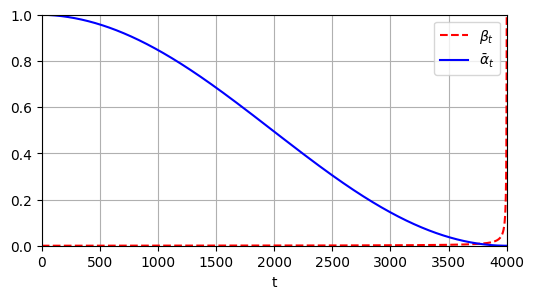

In [ ]:
# extra code – this cell generates and saves Figure 17–21
plt.figure(figsize=(6, 3))
plt.plot(beta, "r--", label=r"$\beta_t$")
plt.plot(alpha_cumprod, "b", label=r"$\bar{\alpha}_t$")
plt.axis([0, T, 0, 1])
plt.grid(True)
plt.xlabel(r"t")
plt.legend()
plt.show()

La función `prepare_batch()` toma un lote de imágenes y añade ruido a cada una, utilizando un tiempo aleatorio diferente entre 1 y $T$ para cada imagen. Devuelve una tupla que contiene las entradas y los objetivos:

* Las entradas son un `dict` que contiene las imágenes con ruido y los tiempos correspondientes. La función utiliza la ecuación (4) del artículo de DDPM para calcular las imágenes con ruido en una sola toma, directamente a partir de las imágenes originales. Es un atajo para el proceso de difusión directo.
* El objetivo es el ruido utilizado para producir las imágenes con ruido.

In [ ]:
def prepare_batch(X):
    X = tf.cast(X[..., tf.newaxis], tf.float32) * 2 - 1  # scale from –1 to +1
    X_shape = tf.shape(X)
    t = tf.random.uniform([X_shape[0]], minval=1, maxval=T + 1, dtype=tf.int32)
    alpha_cm = tf.gather(alpha_cumprod, t)
    alpha_cm = tf.reshape(alpha_cm, [X_shape[0]] + [1] * (len(X_shape) - 1))
    noise = tf.random.normal(X_shape)
    return {
        "X_noisy": alpha_cm ** 0.5 * X + (1 - alpha_cm) ** 0.5 * noise,
        "time": t,
    }, noise

Ahora preparemos un `tf.data.Dataset` para el entrenamiento y uno para la validación.

In [ ]:
def prepare_dataset(X, batch_size=32, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices(X)
    if shuffle:
        ds = ds.shuffle(10_000)
    return ds.batch(batch_size).map(prepare_batch).prefetch(1)

tf.random.set_seed(43)  # extra code – ensures reproducibility on CPU
train_set = prepare_dataset(X_train, batch_size=32, shuffle=True)
valid_set = prepare_dataset(X_valid, batch_size=32)

A modo de rápida comprobación, echemos un vistazo a algunas muestras de entrenamiento, junto con el ruido correspondiente para predecir y las imágenes originales (que obtenemos al restar el ruido escalado adecuadamente de la imagen ruidosa escalada adecuadamente):

Original images


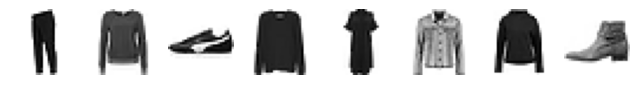

Time steps: [3405  312 3441 1991 2443 1657 3308 1151]
Noisy images


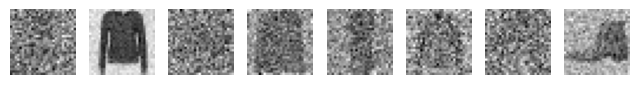

Noise to predict


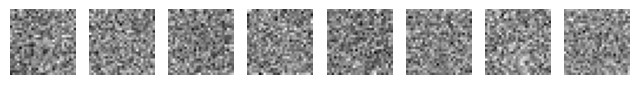

In [ ]:
# extra code – just a quick sanity check

def subtract_noise(X_noisy, time, noise):
    X_shape = tf.shape(X_noisy)
    alpha_cm = tf.gather(alpha_cumprod, time)
    alpha_cm = tf.reshape(alpha_cm, [X_shape[0]] + [1] * (len(X_shape) - 1))
    return (X_noisy - (1 - alpha_cm) ** 0.5 * noise) / alpha_cm ** 0.5

X_dict, Y_noise = list(train_set.take(1))[0]  # get the first batch
X_original = subtract_noise(X_dict["X_noisy"], X_dict["time"], Y_noise)

print("Original images")
plot_multiple_images(X_original[:8].numpy())
plt.show()
print("Time steps:", X_dict["time"].numpy()[:8])
print("Noisy images")
plot_multiple_images(X_dict["X_noisy"][:8].numpy())
plt.show()
print("Noise to predict")
plot_multiple_images(Y_noise[:8].numpy())
plt.show()

Ahora estamos listos para construir el modelo de difusión. Necesitará procesar tanto imágenes como tiempos. Codificaremos los tiempos mediante una codificación sinusoidal, como se sugiere en el artículo de DDPM, al igual que en el artículo [Attention is all you need](https://arxiv.org/abs/1706.03762). Dado un vector de _m_ enteros que representan índices de tiempo (enteros), la capa devuelve una matriz _m_ × _d_, donde _d_ es el tamaño de incrustación elegido.

In [ ]:
# extra code – implements a custom time encoding layer

embed_size = 64

class TimeEncoding(tf.keras.layers.Layer):
    def __init__(self, T, embed_size, dtype=tf.float32, **kwargs):
        super().__init__(dtype=dtype, **kwargs)
        assert embed_size % 2 == 0, "embed_size must be even"
        p, i = np.meshgrid(np.arange(T + 1), 2 * np.arange(embed_size // 2))
        t_emb = np.empty((T + 1, embed_size))
        t_emb[:, ::2] = np.sin(p / 10_000 ** (i / embed_size)).T
        t_emb[:, 1::2] = np.cos(p / 10_000 ** (i / embed_size)).T
        self.time_encodings = tf.constant(t_emb.astype(self.dtype))

    def call(self, inputs):
        return tf.gather(self.time_encodings, inputs)

Ahora construyamos el modelo. En el artículo sobre DDPM mejorado, se utiliza un modelo UNet. Crearemos un modelo similar a UNet que procesa la imagen mediante capas `Conv2D` + `BatchNormalization` y conexiones de salto, reduciendo gradualmente la resolución de la imagen (utilizando capas `MaxPooling` con `strides=2`) y luego volviéndola a aumentar (utilizando capas `Upsampling2D`). Las conexiones de salto también se añaden en las partes de reducción y sobremuestreo. También añadimos las codificaciones de tiempo a la salida de cada bloque, tras pasarlos por una capa `Dense` para ajustar su tamaño.

* **Nota**: La codificación de tiempo de una imagen se añade a cada píxel de la imagen, a lo largo del último eje (canales). Por lo tanto, el número de unidades en la capa `Conv2D` debe corresponder al tamaño de la incrustación, y debemos remodelar el tensor `time_enc` para añadir las dimensiones de ancho y alto. * Esta implementación de UNet se inspiró en el [ejemplo de segmentación de imágenes](https://keras.io/examples/vision/oxford_pets_image_segmentation/) de keras.io, así como en la [implementación oficial de modelos de difusión](https://github.com/hojonathanho/diffusion/blob/master/diffusion_tf/models/unet.py).

In [ ]:
def build_diffusion_model():
    X_noisy = tf.keras.layers.Input(shape=[28, 28, 1], name="X_noisy")
    time_input = tf.keras.layers.Input(shape=[], dtype=tf.int32, name="time")
    time_enc = TimeEncoding(T, embed_size)(time_input)

    dim = 16
    Z = tf.keras.layers.ZeroPadding2D((3, 3))(X_noisy)
    Z = tf.keras.layers.Conv2D(dim, 3)(Z)
    Z = tf.keras.layers.BatchNormalization()(Z)
    Z = tf.keras.layers.Activation("relu")(Z)

    time = tf.keras.layers.Dense(dim)(time_enc)  # adapt time encoding
    Z = time[:, tf.newaxis, tf.newaxis, :] + Z  # add time data to every pixel

    skip = Z
    cross_skips = []  # skip connections across the down & up parts of the UNet

    for dim in (32, 64, 128):
        Z = tf.keras.layers.Activation("relu")(Z)
        Z = tf.keras.layers.SeparableConv2D(dim, 3, padding="same")(Z)
        Z = tf.keras.layers.BatchNormalization()(Z)

        Z = tf.keras.layers.Activation("relu")(Z)
        Z = tf.keras.layers.SeparableConv2D(dim, 3, padding="same")(Z)
        Z = tf.keras.layers.BatchNormalization()(Z)

        cross_skips.append(Z)
        Z = tf.keras.layers.MaxPooling2D(3, strides=2, padding="same")(Z)
        skip_link = tf.keras.layers.Conv2D(dim, 1, strides=2,
                                           padding="same")(skip)
        Z = tf.keras.layers.add([Z, skip_link])

        time = tf.keras.layers.Dense(dim)(time_enc)
        Z = time[:, tf.newaxis, tf.newaxis, :] + Z
        skip = Z

    for dim in (64, 32, 16):
        Z = tf.keras.layers.Activation("relu")(Z)
        Z = tf.keras.layers.Conv2DTranspose(dim, 3, padding="same")(Z)
        Z = tf.keras.layers.BatchNormalization()(Z)

        Z = tf.keras.layers.Activation("relu")(Z)
        Z = tf.keras.layers.Conv2DTranspose(dim, 3, padding="same")(Z)
        Z = tf.keras.layers.BatchNormalization()(Z)

        Z = tf.keras.layers.UpSampling2D(2)(Z)

        skip_link = tf.keras.layers.UpSampling2D(2)(skip)
        skip_link = tf.keras.layers.Conv2D(dim, 1, padding="same")(skip_link)
        Z = tf.keras.layers.add([Z, skip_link])

        time = tf.keras.layers.Dense(dim)(time_enc)
        Z = time[:, tf.newaxis, tf.newaxis, :] + Z
        Z = tf.keras.layers.concatenate([Z, cross_skips.pop()], axis=-1)
        skip = Z

    outputs = tf.keras.layers.Conv2D(1, 3, padding="same")(Z)[:, 2:-2, 2:-2]
    return tf.keras.Model(inputs=[X_noisy, time_input], outputs=[outputs])

Let's train the model!

In [ ]:
tf.random.set_seed(42)  # extra code – ensures reproducibility on the CPU
model = build_diffusion_model()
model.compile(loss=tf.keras.losses.Huber(), optimizer=tf.keras.optimizers.Nadam())

# extra code – adds a ModelCheckpoint callback
checkpoint_cb = tf.keras.callbacks.ModelCheckpoint("my_diffusion_model",
                                                   save_best_only=True)



In [ ]:
history = model.fit(train_set, validation_data=valid_set, epochs=10,
                    callbacks=[checkpoint_cb])  # extra code

Epoch 1/10
1719/1719 [==============================] - 72s 27ms/step - loss: 0.1065 - val_loss: 0.0716
Epoch 2/10
1719/1719 [==============================] - 45s 26ms/step - loss: 0.0635 - val_loss: 0.0596
Epoch 3/10
1719/1719 [==============================] - 45s 26ms/step - loss: 0.0537 - val_loss: 0.0501
Epoch 4/10
1719/1719 [==============================] - 44s 26ms/step - loss: 0.0493 - val_loss: 0.0495
Epoch 5/10
1719/1719 [==============================] - 44s 26ms/step - loss: 0.0468 - val_loss: 0.0456
Epoch 6/10
1719/1719 [==============================] - 44s 26ms/step - loss: 0.0454 - val_loss: 0.0455
Epoch 7/10
1719/1719 [==============================] - 44s 25ms/step - loss: 0.0444 - val_loss: 0.0435
Epoch 8/10
1719/1719 [==============================] - 38s 22ms/step - loss: 0.0438 - val_loss: 0.0444
Epoch 9/10
1719/1719 [==============================] - 44s 26ms/step - loss: 0.0429 - val_loss: 0.0420
Epoch 10/10
1719/1719 [==============================] - 45s 26m

Ahora que el modelo está entrenado, podemos usarlo para generar nuevas imágenes. Para ello, simplemente generamos ruido gaussiano y suponemos que este es el resultado del proceso de difusión, en el tiempo $T$. Luego, usamos el modelo para predecir la imagen en el tiempo $T - 1$, lo volvemos a llamar para obtener $T - 2$, y así sucesivamente, eliminando un poco de ruido en cada paso. Al final, obtenemos una imagen que parece provenir del conjunto de datos Fashion MNIST. La ecuación para este proceso inverso se encuentra en la parte superior de la página 4 del artículo de DDPM (paso 4 del algoritmo 2).

In [ ]:
def generate(model, batch_size=32):
    X = tf.random.normal([batch_size, 28, 28, 1])
    for t in range(T - 1, 0, -1):
        print(f"\rt = {t}", end=" ")  # extra code – show progress
        noise = (tf.random.normal if t > 1 else tf.zeros)(tf.shape(X))
        X_noise = model({"X_noisy": X, "time": tf.constant([t] * batch_size)})
        X = (
            1 / alpha[t] ** 0.5
            * (X - beta[t] / (1 - alpha_cumprod[t]) ** 0.5 * X_noise)
            + (1 - alpha[t]) ** 0.5 * noise
        )
    return X

tf.random.set_seed(42)  # extra code – ensures reproducibility on the CPU
X_gen = generate(model)  # generated images

t = 3807 

In [ ]:
plot_multiple_images(X_gen.numpy(), 8)
plt.show()

In [ ]:
model.save("model_Difussion_28May2025A_10Epochs.h5")